In [78]:
import numpy as np  
import matplotlib.pyplot as plt

# Used whenever a function is called without an explicit generator.
_default_rng = np.random.default_rng()

## Testing setting up

In [79]:
def initialize_lattice(n, seed=None, startcold=True, rng=None):
    if rng is not None and seed is not None:
        raise ValueError("Pass either seed or rng, not both.")
    if rng is None:
        rng = np.random.default_rng(seed)
    if startcold:
        lattice = np.ones((n, n), dtype=np.int8)
    else:
        lattice = rng.integers(0, 2, size=(n, n), dtype=np.int8)
        lattice[lattice == 0] = -1
    return lattice

In [80]:
def random_spin(lattice, rng=None):
    if rng is None:
        rng = _default_rng
    n = lattice.shape[0]
    i, j = rng.integers(0, n, size=2)
    return i, j

In [81]:
def Hamiltonian(lattice, J=1):
    right_neighbours = np.roll(lattice, shift=-1, axis=1)
    bottom_neighbours = np.roll(lattice, shift=-1, axis=0)
    return -J * np.sum(lattice * (right_neighbours + bottom_neighbours))


In [82]:
def magnetization(lattice):
    return np.sum(lattice) / lattice.size

In [83]:
def metropolis_update(lattice, beta, rng=None, J=1):
    """Attempt one spin flip in place and return (delta_energy, delta_spin_sum)."""
    if rng is None:
        rng = _default_rng

    n = lattice.shape[0]
    i, j = random_spin(lattice, rng)
    spin = int(lattice[i, j])
    neighbour_sum = (
        lattice[(i + 1) % n, j]
        + lattice[(i - 1) % n, j]
        + lattice[i, (j + 1) % n]
        + lattice[i, (j - 1) % n]
    )
    delta_energy = 2 * J * spin * int(neighbour_sum)

    if delta_energy <= 0 or rng.random() < np.exp(-beta * delta_energy):
        lattice[i, j] = -spin
        return delta_energy, -2 * spin
    return 0, 0


def metropolis_step(lattice, beta, rng=None, J=1):
    """Backward-compatible one-step function used by the earlier cells."""
    metropolis_update(lattice, beta, rng=rng, J=J)
    return lattice, Hamiltonian(lattice, J=J), magnetization(lattice)

In [ ]:
t=200000
H_dyn=np.zeros(t)
M=np.zeros(t)
lattice = initialize_lattice(100)
for i in range(t):
    lattice, H_dyn[i], M[i] = metropolis_step(lattice, beta=1.0)
    


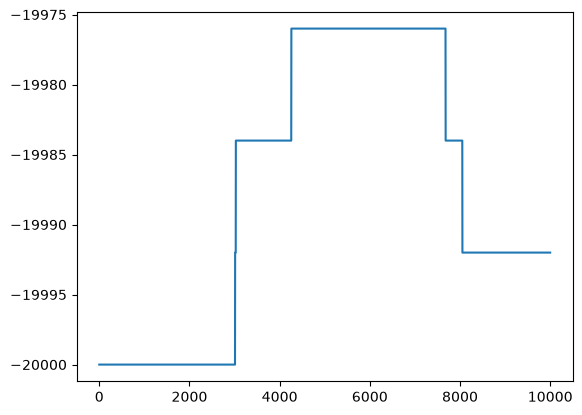

In [ ]:
plt.plot(H_dyn)

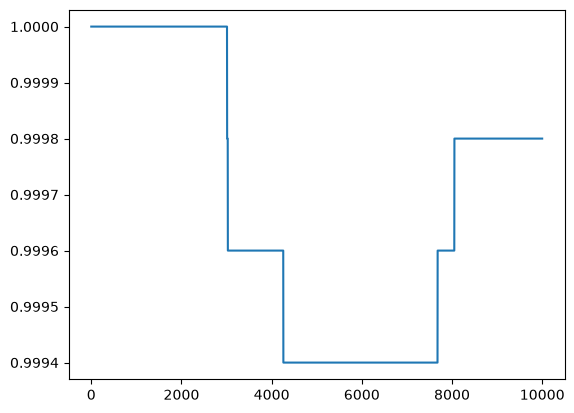

In [ ]:
plt.plot(M)

I expreienced that altough I used the same seed, the equillibrium was reached in different timesteps in different runs, both in magnetization and in energy, sometimes around 2000 sometimes around 8000

## Getting it compatible with $m(0.5)=0.911319...$

In [ ]:
t=200000
H_dyn=np.zeros(t)
M=np.zeros(t)
lattice = initialize_lattice(15)
for i in range(t):
    lattice, H_dyn[i], M[i] = metropolis_step(lattice, beta=0.5)
    

In [ ]:
M_eq=M[10000:]
H_eq=H_dyn[10000:]


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)

ax.plot(M, color="#2563EB", linewidth=2, label="M")

ax.set_title("M", fontsize=14, fontweight="bold")
ax.set_xlabel("Index", fontsize=11)
ax.set_ylabel("Value", fontsize=11)

ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()


In [ ]:
print(np.mean(M[10000:]))
print(np.std(M[10000:]))
print(np.var(M[10000:]))


0.9092513216374271
0.04914170728555771
0.0024149073949394357


## Hot/cold ensemble relaxation

`run_relaxation_ensemble` runs the same number of cold and hot starts. Time is stored in Monte Carlo sweeps (attempted flips divided by the number of lattice sites). For `M`, absolute magnetization is used by default so that positive and negative ordered states do not cancel.

In [ ]:
def run_trajectory(lattice_size, beta, n_steps, startcold, observable, rng,
                   J=1, measure_every=1, absolute_magnetization=True):
    """Run one trajectory and return its sampled observable."""
    if n_steps < 1 or measure_every < 1:
        raise ValueError("n_steps and measure_every must be positive integers.")

    observable = observable.upper()
    if observable not in {"H", "M"}:
        raise ValueError("observable must be 'H' or 'M'.")

    lattice = initialize_lattice(lattice_size, startcold=startcold, rng=rng)
    energy = float(Hamiltonian(lattice, J=J))
    spin_sum = int(np.sum(lattice))

    sample_steps = np.arange(0, n_steps + 1, measure_every, dtype=int)
    if sample_steps[-1] != n_steps:
        sample_steps = np.append(sample_steps, n_steps)
    values = np.empty(sample_steps.size, dtype=float)

    def current_value():
        if observable == "H":
            return energy
        value = spin_sum / lattice.size
        return abs(value) if absolute_magnetization else value

    values[0] = current_value()
    previous_step = 0
    for sample_index, target_step in enumerate(sample_steps[1:], start=1):
        for _ in range(target_step - previous_step):
            delta_energy, delta_spin_sum = metropolis_update(
                lattice, beta, rng=rng, J=J
            )
            energy += delta_energy
            spin_sum += delta_spin_sum
        values[sample_index] = current_value()
        previous_step = target_step

    time_sweeps = sample_steps / lattice.size
    return time_sweeps, values


def fit_relaxation_exponential(time, difference, fit_start=0, fit_stop=None,
                               fit_offset=False):
    """Fit D(t) = A exp(-t/tau) + C using only NumPy."""
    time = np.asarray(time, dtype=float)
    difference = np.asarray(difference, dtype=float)
    stop = len(time) if fit_stop is None else fit_stop
    t = time[fit_start:stop]
    y = difference[fit_start:stop]
    finite = np.isfinite(t) & np.isfinite(y)
    t, y = t[finite], y[finite]
    if t.size < 3 or t[-1] <= t[0]:
        raise ValueError("The fit window must contain at least three distinct samples.")

    # Shift the fit window to avoid an unnecessary exp(-large number).
    t_origin = t[0]
    shifted_t = t - t_origin
    positive_dt = np.diff(t)
    positive_dt = positive_dt[positive_dt > 0]
    dt = positive_dt.min()
    span = shifted_t[-1]
    low_tau = max(dt / 10, np.finfo(float).eps)
    high_tau = max(span * 100, low_tau * 10)

    best = None
    for _ in range(3):
        taus = np.geomspace(low_tau, high_tau, 300)
        for tau in taus:
            exponential = np.exp(-shifted_t / tau)
            if fit_offset:
                x_centered = exponential - exponential.mean()
                denominator = np.dot(x_centered, x_centered)
                amplitude = (np.dot(x_centered, y - y.mean()) / denominator
                             if denominator > 0 else 0.0)
                offset = y.mean() - amplitude * exponential.mean()
            else:
                amplitude = np.dot(exponential, y) / np.dot(exponential, exponential)
                offset = 0.0
            residual = y - (amplitude * exponential + offset)
            rss = np.dot(residual, residual)
            if best is None or rss < best[0]:
                best = (rss, tau, amplitude, offset)

        best_index = np.searchsorted(taus, best[1])
        lower_index = max(0, best_index - 2)
        upper_index = min(len(taus) - 1, best_index + 1)
        low_tau, high_tau = taus[lower_index], taus[upper_index]

    rss, tau, amplitude_at_origin, offset = best
    amplitude = amplitude_at_origin * np.exp(t_origin / tau)
    fitted_curve = amplitude * np.exp(-time / tau) + offset
    return {
        "amplitude": amplitude,
        "offset": offset,
        "tau": tau,
        "relaxation_time": tau,
        "time_to_1_percent": tau * np.log(100),
        "fitted_curve": fitted_curve,
        "rmse": np.sqrt(rss / t.size),
        "fit_start": fit_start,
        "fit_stop": stop,
        "fit_offset": fit_offset,
    }


def run_relaxation_ensemble(lattice_size, beta, n_runs, n_steps, observable="H",
                            J=1, seed=None, measure_every=1,
                            absolute_magnetization=True, fit_start=0,
                            fit_stop=None, fit_offset=False):
    """Run n_runs cold starts and n_runs hot starts and fit their difference."""
    if lattice_size < 2 or n_runs < 2:
        raise ValueError("lattice_size and n_runs must both be at least 2.")

    seed_sequences = np.random.SeedSequence(seed).spawn(2 * n_runs)
    cold_runs = []
    hot_runs = []
    time_sweeps = None

    for run_index in range(n_runs):
        cold_rng = np.random.default_rng(seed_sequences[run_index])
        hot_rng = np.random.default_rng(seed_sequences[n_runs + run_index])
        time_sweeps, cold_values = run_trajectory(
            lattice_size, beta, n_steps, True, observable, cold_rng,
            J=J, measure_every=measure_every,
            absolute_magnetization=absolute_magnetization
        )
        _, hot_values = run_trajectory(
            lattice_size, beta, n_steps, False, observable, hot_rng,
            J=J, measure_every=measure_every,
            absolute_magnetization=absolute_magnetization
        )
        cold_runs.append(cold_values)
        hot_runs.append(hot_values)

    cold_runs = np.asarray(cold_runs)
    hot_runs = np.asarray(hot_runs)
    cold_mean = cold_runs.mean(axis=0)
    hot_mean = hot_runs.mean(axis=0)
    cold_sem = cold_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
    hot_sem = hot_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
    difference = cold_mean - hot_mean
    difference_sem = np.sqrt(cold_sem**2 + hot_sem**2)
    fit = fit_relaxation_exponential(
        time_sweeps, difference, fit_start=fit_start, fit_stop=fit_stop,
        fit_offset=fit_offset
    )

    result = {
        "parameters": {
            "lattice_size": lattice_size, "beta": beta, "n_runs": n_runs,
            "n_steps": n_steps, "observable": observable.upper(), "J": J,
            "seed": seed, "measure_every": measure_every,
            "absolute_magnetization": absolute_magnetization,
        },
        "time": time_sweeps,
        "cold_runs": cold_runs,
        "hot_runs": hot_runs,
        "cold_mean": cold_mean,
        "hot_mean": hot_mean,
        "cold_sem": cold_sem,
        "hot_sem": hot_sem,
        "difference": difference,
        "difference_sem": difference_sem,
        "fit": fit,
    }
    return result


def plot_relaxation(result):
    """Plot the stored ensemble averages, difference, and exponential fit."""
    time = result["time"]
    label = result["parameters"]["observable"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(time, result["cold_mean"], label="cold average")
    axes[0].plot(time, result["hot_mean"], label="hot average")
    axes[0].set(xlabel="Monte Carlo sweeps", ylabel=label)
    axes[0].legend()

    axes[1].plot(time, result["difference"], label="cold - hot")
    axes[1].plot(time, result["fit"]["fitted_curve"], "--",
                 label=f"fit: tau = {result['fit']['tau']:.3g} sweeps")
    axes[1].set(xlabel="Monte Carlo sweeps", ylabel=f"difference in {label}")
    axes[1].legend()
    fig.tight_layout()
    return fig, axes

Relaxation time: 35.829 sweeps
Time to 1%: 164.998 sweeps


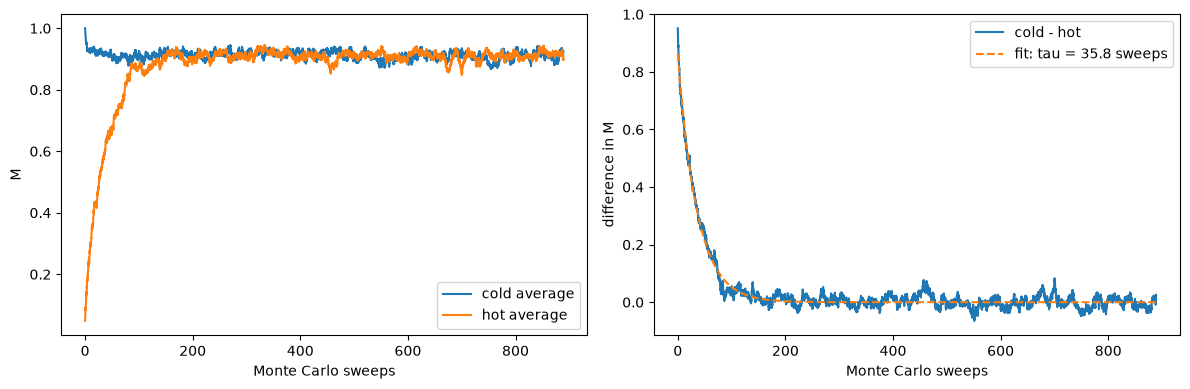

In [ ]:
# Example: the complete result is retained in relaxation_M for later analysis.
relaxation_M = run_relaxation_ensemble(
    lattice_size=15,
    beta=0.5,
    n_runs=20,       # 10 cold runs and 10 hot runs
    n_steps=200000,  # attempted single-spin flips per run
    observable="M",
    measure_every=20,
    seed=42,
)



In [ ]:
print(f"Relaxation time: {relaxation_M['fit']['tau']:.3f} sweeps that is {relaxation_M['fit']['tau'] * 225:.3f} steps")
print(f"Time to 1%: {relaxation_M['fit']['time_to_1_percent']:.3f} sweeps that is ")
plot_relaxation(relaxation_M);



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Equilibrium energy fluctuations
H = np.asarray(H_eq) - np.mean(H_eq)

# Normalized autocorrelation
acf = np.correlate(H, H, mode='full')[len(H)-1:]
acf = acf / acf[0]

# Exponential autocorrelation time: rho(tau) = 1/e
level = 1 / np.e
i = np.where(acf <= level)[0][0]

# Linear interpolation between the two surrounding points
tau_exp = (i - 1) + (acf[i-1] - level) / (acf[i-1] - acf[i])
tau_exp_sweeps = tau_exp / 225

print(f"Exponential autocorrelation time:")
print(f"tau_exp = {tau_exp:.2f} steps")
print(f"tau_exp = {tau_exp_sweeps:.3f} sweeps")

# Plot
plt.plot(acf[:max(10, int(5*tau_exp))])
plt.axhline(level, linestyle='--', label='1/e')
plt.axvline(tau_exp, linestyle='--', label=f'tau = {tau_exp:.1f} steps')
plt.xlabel("Lag [steps]")
plt.ylabel("Normalized autocorrelation")
plt.legend()
plt.show()


In [ ]:
# Find first zero crossing
negative = np.where(acf <= 0)[0]
cutoff = negative[0] if len(negative) > 0 else len(acf)

# Integrated autocorrelation time
tau_int = 0.5 + np.sum(acf[1:cutoff])
tau_int_sweeps = tau_int / 225

# Effective number of independent measurements
N_eff = len(H_eq) / (2 * tau_int)

print(f"Integrated autocorrelation time:")
print(f"tau_int = {tau_int:.2f} steps")
print(f"tau_int = {tau_int_sweeps:.3f} sweeps")
print(f"Effective independent measurements ≈ {N_eff:.0f}")


Integrated autocorrelation time:
tau_int = 484.10 steps
tau_int = 2.152 sweeps
Effective independent measurements ≈ 196


In [ ]:
def block_magnetization_statistics(magnetization_values, n_blocks):
    """Estimate the mean and its uncertainty using contiguous time blocks.

    The time series is divided into ``n_blocks`` contiguous blocks. The
    variance of the overall mean is estimated from the sample variance of
    the block means: Var(mean) = Var(block means) / n_blocks.
    """
    values = np.asarray(magnetization_values, dtype=float)

    if values.ndim != 1:
        raise ValueError("magnetization_values must be a one-dimensional array.")
    if not isinstance(n_blocks, (int, np.integer)) or isinstance(n_blocks, bool):
        raise TypeError("n_blocks must be an integer.")
    if n_blocks < 2:
        raise ValueError("n_blocks must be at least 2 to estimate a variance.")
    if n_blocks > values.size:
        raise ValueError("n_blocks cannot exceed the number of measurements.")
    if not np.all(np.isfinite(values)):
        raise ValueError("magnetization_values must contain only finite values.")

    # Use equal-sized blocks so every block mean has the same weight.
    block_size = values.size // n_blocks
    n_used = block_size * n_blocks
    blocks = values[:n_used].reshape(n_blocks, block_size)
    block_means = blocks.mean(axis=1)
    overall_mean = block_means.mean()
    block_mean_variance = block_means.var(ddof=1)
    mean_variance = block_mean_variance / n_blocks

    return {
        "block_means": block_means,
        "overall_mean": overall_mean,
        "block_mean_variance": block_mean_variance,
        "mean_variance": mean_variance,
        "standard_error": np.sqrt(mean_variance),
        "block_size": block_size,
        "n_used": n_used,
        "n_discarded": values.size - n_used,
    }


# Example (discard the equilibration part before doing the analysis):
# stats = block_magnetization_statistics(M[150000:], n_blocks=20)
# print(stats)


In [ ]:
block_counts = [10, 20,30, 40, 50, 60, 70, 80, 90, 120, 150, 160, 165, 174, 180, 185, 190, 198, 200, 220, 250, 290, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2500]
blocking_results = {
    n_blocks: block_magnetization_statistics(M_eq, n_blocks)
    for n_blocks in block_counts
}

print(f"{'blocks':>6} {'block size [steps]':>18} {'block size [sweeps]':>19} "  
      f"{'discarded':>10} {'mean M':>12} {'standard error':>16}")
for n_blocks, result in blocking_results.items():
    print(
        f"{n_blocks:6d} {result['block_size']:18d} "
        f"{result['block_size'] / lattice.size:19.3f} "
        f"{result['n_discarded']:10d} {result['overall_mean']:12.8f} "
        f"{result['standard_error']:16.8f}"
    )



In [ ]:
# Effect of simulation length on blocking uncertainty
simulation_lengths = np.arange(200_000, 1_000_001, 100_000)
block_size = 3_000       # attempted spin flips per block
burn_in = 10_000
lattice_size = 15
beta = 0.5

rng = np.random.default_rng(42)
lattice = initialize_lattice(
    lattice_size,
    startcold=True,
    rng=rng,
)

# Run one long trajectory and record magnetization after every attempted flip
max_steps = simulation_lengths[-1]
magnetization_history = np.empty(max_steps)

spin_sum = int(np.sum(lattice))

for step in range(max_steps):
    _, delta_spin_sum = metropolis_update(lattice, beta, rng=rng)
    spin_sum += delta_spin_sum
    magnetization_history[step] = spin_sum / lattice.size

results = []

for n_steps in simulation_lengths:
    # Discard equilibration and use only complete 3000-step blocks
    values = magnetization_history[burn_in:n_steps]

    n_blocks = len(values) // block_size
    n_used = n_blocks * block_size
    values = values[:n_used]

    blocks = values.reshape(n_blocks, block_size)
    block_means = blocks.mean(axis=1)

    mean_magnetization = block_means.mean()
    standard_error = block_means.std(ddof=1) / np.sqrt(n_blocks)

    results.append(
        {
            "simulation_length": n_steps,
            "n_used": n_used,
            "n_blocks": n_blocks,
            "mean": mean_magnetization,
            "uncertainty": standard_error,
        }
    )

# Display results
print(
    f"{'total steps':>12} "
    f"{'used steps':>12} "
    f"{'blocks':>8} "
    f"{'mean M':>12} "
    f"{'uncertainty':>14}"
)

for result in results:
    print(
        f"{result['simulation_length']:12d} "
        f"{result['n_used']:12d} "
        f"{result['n_blocks']:8d} "
        f"{result['mean']:12.8f} "
        f"{result['uncertainty']:14.8f}"
    )

# Plot uncertainty against simulation length
lengths = np.array([r["simulation_length"] for r in results])
used_steps = np.array([r["n_used"] for r in results])
uncertainties = np.array([r["uncertainty"] for r in results])

# Expected 1/sqrt(N) scaling, normalized to the first measurement
inverse_sqrt_reference = (
    uncertainties[0] * np.sqrt(used_steps[0] / used_steps)
)

plt.figure(figsize=(7, 4.5))
plt.plot(
    lengths,
    uncertainties,
    "o-",
    label="Blocking uncertainty",
)
plt.plot(
    lengths,
    inverse_sqrt_reference,
    "--",
    label=r"$1/\sqrt{N}$ reference",
)

plt.xlabel("Simulation length [attempted spin flips]")
plt.ylabel("Standard error of mean magnetization")
plt.title(f"Blocking uncertainty, block size = {block_size} steps")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Magnetization versus lattice size using the same number of sweeps

lattice_sizes = [5, 10, 15, 20, 25, 30, 40, 50]

beta = 0.5
n_sweeps = 1_000
equilibration_sweeps = 200

seed_sequences = np.random.SeedSequence(42).spawn(len(lattice_sizes))
results_by_size = []

for L, seed_sequence in zip(lattice_sizes, seed_sequences):
    rng = np.random.default_rng(seed_sequence)
    lattice = initialize_lattice(L, startcold=True, rng=rng)

    spin_sum = int(np.sum(lattice))
    magnetization_per_sweep = np.empty(n_sweeps)

    # One sweep = L^2 attempted spin flips
    for sweep in range(n_sweeps):
        for _ in range(lattice.size):
            _, delta_spin_sum = metropolis_update(
                lattice,
                beta,
                rng=rng,
            )
            spin_sum += delta_spin_sum

        magnetization_per_sweep[sweep] = abs(
            spin_sum / lattice.size
        )

    equilibrium_values = magnetization_per_sweep[
        equilibration_sweeps:
    ]

    mean_magnetization = equilibrium_values.mean()

    results_by_size.append(
        {
            "L": L,
            "sites": L**2,
            "sweeps": n_sweeps,
            "attempted_flips": n_sweeps * L**2,
            "mean_magnetization": mean_magnetization,
        }
    )

    print(
        f"L={L:2d}: "
        f"attempted flips={n_sweeps * L**2:9d}, "
        f"<|M|>={mean_magnetization:.6f}"
    )

# Display a summary table
print()
print(
    f"{'L':>4} "
    f"{'sites':>7} "
    f"{'sweeps':>8} "
    f"{'attempted flips':>17} "
    f"{'<|M|>':>12}"
)

for result in results_by_size:
    print(
        f"{result['L']:4d} "
        f"{result['sites']:7d} "
        f"{result['sweeps']:8d} "
        f"{result['attempted_flips']:17d} "
        f"{result['mean_magnetization']:12.8f}"
    )

# Plot equilibrium magnetization against linear lattice size
sizes = np.array([result["L"] for result in results_by_size])
magnetizations = np.array([
    result["mean_magnetization"]
    for result in results_by_size
])

plt.figure(figsize=(7, 4.5))
plt.plot(
    sizes,
    magnetizations,
    "o-",
    label="Monte Carlo result",
)

# Exact infinite-lattice magnetization for the 2D Ising model
exact_magnetization = (
    1 - np.sinh(2 * beta) ** (-4)
) ** (1 / 8)
plt.xlabel("Linear lattice size $L$")
plt.ylabel(r"Equilibrium magnetization $\langle |M| \rangle$")
plt.title(
    f"Magnetization versus lattice size at "
    fr"$\beta={beta}$ ({n_sweeps} sweeps)"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Analysis for $\beta=0.45$

The same checks used for $\beta=0.5$ are repeated here. Because $\beta=0.45$ is closer to the critical inverse temperature, its equilibration time, autocorrelation time, and block size are estimated independently. One sweep is $L^2$ attempted single-spin flips.


### Equilibration and discarded configurations

Ordered and random initial states are evolved independently. Their mean absolute magnetizations are compared, and an exponential fit to their difference gives a conservative 1% discard time.


Relaxation time: 40.32 sweeps
Recommended 1% discard: 185.69 sweeps
For L=15, discard about 41780 attempted flips


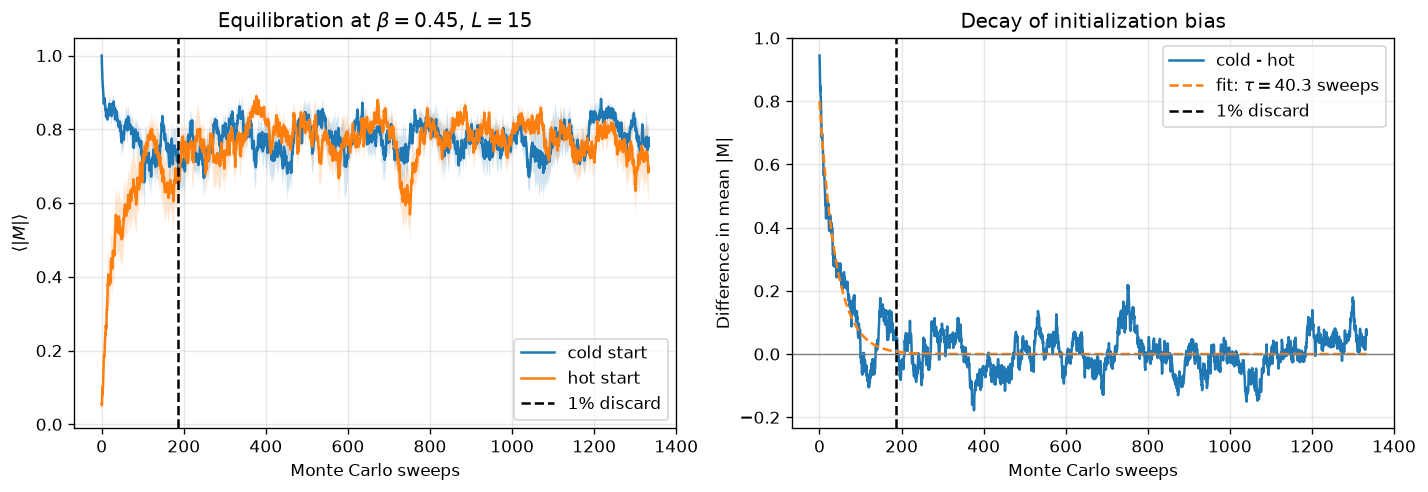

In [1]:
beta_045 = 0.45
reference_L_045 = 15
reference_sites_045 = reference_L_045**2

relaxation_045 = run_relaxation_ensemble(
    lattice_size=reference_L_045,
    beta=beta_045,
    n_runs=12,          # 12 cold and 12 hot trajectories
    n_steps=300_000,
    observable="M",
    measure_every=100,
    seed=450,
)

discard_sweeps_045 = relaxation_045["fit"]["time_to_1_percent"]
discard_steps_045 = int(np.ceil(discard_sweeps_045 * reference_sites_045))

print(f"Relaxation time: {relaxation_045['fit']['tau']:.2f} sweeps")
print(f"Recommended 1% discard: {discard_sweeps_045:.2f} sweeps")
print(f"For L={reference_L_045}, discard about {discard_steps_045} attempted flips")

time = relaxation_045["time"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(time, relaxation_045["cold_mean"], label="cold start")
axes[0].plot(time, relaxation_045["hot_mean"], label="hot start")
axes[0].fill_between(
    time,
    relaxation_045["cold_mean"] - relaxation_045["cold_sem"],
    relaxation_045["cold_mean"] + relaxation_045["cold_sem"],
    alpha=0.2,
)
axes[0].fill_between(
    time,
    relaxation_045["hot_mean"] - relaxation_045["hot_sem"],
    relaxation_045["hot_mean"] + relaxation_045["hot_sem"],
    alpha=0.2,
)
axes[0].axvline(discard_sweeps_045, color="black", ls="--", label="1% discard")
axes[0].set(
    xlabel="Monte Carlo sweeps",
    ylabel=r"$\langle |M|\rangle$",
    title=fr"Equilibration at $\beta={beta_045}$, $L={reference_L_045}$",
)
axes[0].legend()

axes[1].plot(time, relaxation_045["difference"], label="cold - hot")
axes[1].plot(
    time,
    relaxation_045["fit"]["fitted_curve"],
    "--",
    label=fr"fit: $\tau={relaxation_045['fit']['tau']:.1f}$ sweeps",
)
axes[1].axvline(discard_sweeps_045, color="black", ls="--", label="1% discard")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set(
    xlabel="Monte Carlo sweeps",
    ylabel="Difference in mean |M|",
    title="Decay of initialization bias",
)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Autocorrelation and effective sample size

A long equilibrium trajectory is used to estimate the autocorrelation of $|M|$. The integrated autocorrelation time uses a self-consistent window, and the effective sample size accounts for correlated measurements.


Exponential autocorrelation time: 8923.0 attempted flips
Integrated autocorrelation time: 7289.8 attempted flips
Integrated autocorrelation time: 32.40 sweeps
Self-consistent window: 36450 attempted flips
Effective independent measurements: 134.3


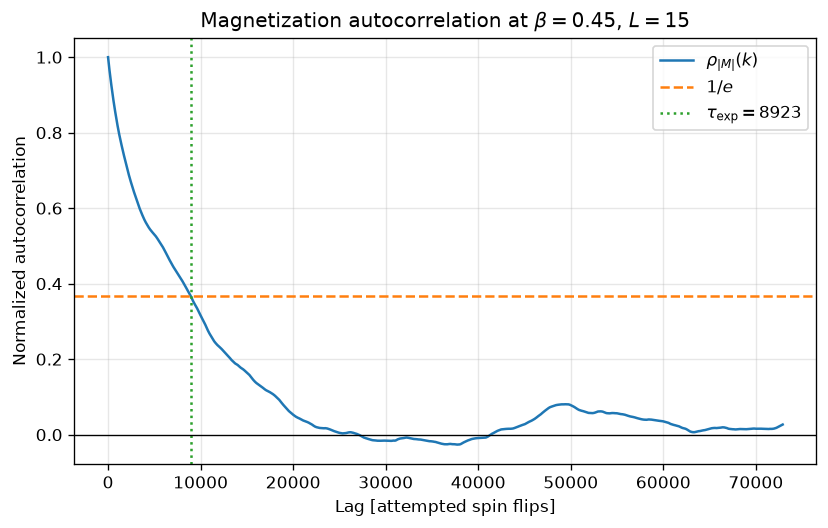

In [2]:
def normalized_acf_fft(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    values = values - values.mean()
    n = len(values)
    n_fft = 1 << (2 * n - 1).bit_length()
    transformed = np.fft.rfft(values, n=n_fft)
    acf_values = np.fft.irfft(transformed * np.conjugate(transformed), n=n_fft)[:n]
    acf_values /= n
    return acf_values / acf_values[0]


def self_consistent_tau(acf_values, window_factor=5.0):
    cumulative_tau = 0.5 + np.cumsum(acf_values[1:])
    windows = np.arange(1, len(acf_values))
    valid = np.flatnonzero(
        (windows >= window_factor * cumulative_tau)
        & (cumulative_tau > 0)
    )
    if valid.size:
        index = valid[0]
    else:
        index = min(len(cumulative_tau) - 1, len(acf_values) // 10)
    return float(cumulative_tau[index]), int(windows[index])


max_steps_045 = 2_000_000
rng = np.random.default_rng(451)
lattice = initialize_lattice(reference_L_045, startcold=True, rng=rng)
spin_sum = int(np.sum(lattice))
magnetization_history_045 = np.empty(max_steps_045)

for step in range(max_steps_045):
    _, delta_spin_sum = metropolis_update(lattice, beta_045, rng=rng)
    spin_sum += delta_spin_sum
    magnetization_history_045[step] = abs(spin_sum / lattice.size)

discard_steps_045 = max(10_000, discard_steps_045)
equilibrium_magnetization_045 = magnetization_history_045[discard_steps_045:]
acf_045 = normalized_acf_fft(equilibrium_magnetization_045)
tau_int_045, acf_window_045 = self_consistent_tau(acf_045)

crossings = np.flatnonzero(acf_045 <= 1 / np.e)
tau_exp_045 = float(crossings[0]) if crossings.size else np.nan
tau_int_sweeps_045 = tau_int_045 / reference_sites_045
effective_samples_045 = len(equilibrium_magnetization_045) / (2 * tau_int_045)

print(f"Exponential autocorrelation time: {tau_exp_045:.1f} attempted flips")
print(f"Integrated autocorrelation time: {tau_int_045:.1f} attempted flips")
print(f"Integrated autocorrelation time: {tau_int_sweeps_045:.2f} sweeps")
print(f"Self-consistent window: {acf_window_045} attempted flips")
print(f"Effective independent measurements: {effective_samples_045:.1f}")

max_lag = min(len(acf_045), max(1000, int(10 * tau_int_045)))
lags = np.arange(max_lag)

plt.figure(figsize=(7, 4.5))
plt.plot(lags, acf_045[:max_lag], label=r"$\rho_{|M|}(k)$")
plt.axhline(1 / np.e, color="C1", ls="--", label=r"$1/e$")
if np.isfinite(tau_exp_045):
    plt.axvline(tau_exp_045, color="C2", ls=":", label=fr"$\tau_{{\rm exp}}={tau_exp_045:.0f}$")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("Lag [attempted spin flips]")
plt.ylabel("Normalized autocorrelation")
plt.title(fr"Magnetization autocorrelation at $\beta={beta_045}$, $L={reference_L_045}$")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Blocking and simulation-length uncertainty

The left panel scans the block size to find the uncertainty plateau. A conservative block length derived from the magnetization autocorrelation is then used to show how uncertainty changes with total simulation length.


Chosen block size: 72900 attempted flips (324.0 sweeps)
     steps   blocks     mean |M|    uncertainty
    600000        7   0.74945706     0.03594122
    800000       10   0.74556246     0.02604400
   1000000       13   0.75885314     0.02114278
   1200000       15   0.76512264     0.01874053
   1400000       18   0.76797299     0.01637693
   1600000       21   0.77461278     0.01473404
   1800000       24   0.78114892     0.01342865
   2000000       26   0.78258464     0.01243287


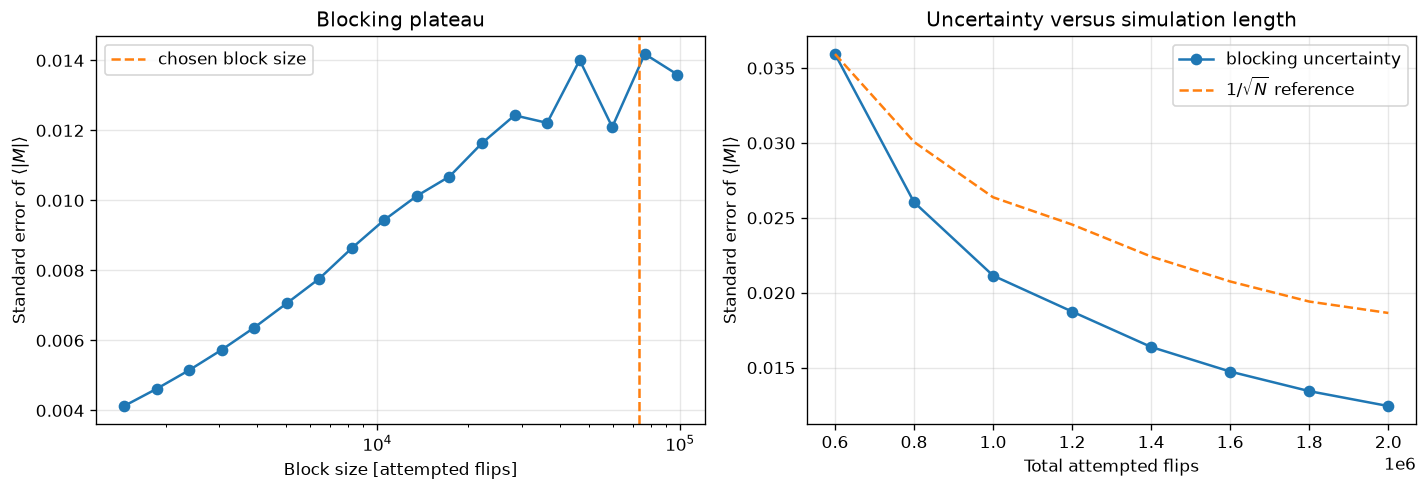

In [3]:
minimum_block_045 = max(100, int(tau_int_045 / 5))
maximum_block_045 = min(
    len(equilibrium_magnetization_045) // 20,
    max(minimum_block_045 + 1, int(30 * tau_int_045)),
)
block_sizes_045 = np.unique(
    np.geomspace(minimum_block_045, maximum_block_045, 18).astype(int)
)

blocking_errors_045 = []
blocking_counts_045 = []
for block_size in block_sizes_045:
    n_blocks = len(equilibrium_magnetization_045) // block_size
    block_means = equilibrium_magnetization_045[:n_blocks * block_size].reshape(
        n_blocks, block_size
    ).mean(axis=1)
    blocking_errors_045.append(block_means.std(ddof=1) / np.sqrt(n_blocks))
    blocking_counts_045.append(n_blocks)
blocking_errors_045 = np.asarray(blocking_errors_045)

chosen_block_045 = int(np.ceil(10 * tau_int_045 / 100) * 100)
chosen_block_045 = min(chosen_block_045, len(equilibrium_magnetization_045) // 20)

candidate_lengths_045 = np.arange(400_000, max_steps_045 + 1, 200_000)
length_results_045 = []
for total_steps in candidate_lengths_045:
    values = magnetization_history_045[discard_steps_045:total_steps]
    n_blocks = len(values) // chosen_block_045
    if n_blocks < 5:
        continue
    block_means = values[:n_blocks * chosen_block_045].reshape(
        n_blocks, chosen_block_045
    ).mean(axis=1)
    length_results_045.append(
        (
            total_steps,
            n_blocks,
            block_means.mean(),
            block_means.std(ddof=1) / np.sqrt(n_blocks),
            n_blocks * chosen_block_045,
        )
    )

print(f"Chosen block size: {chosen_block_045} attempted flips "
      f"({chosen_block_045 / reference_sites_045:.1f} sweeps)")
print(f"{'steps':>10} {'blocks':>8} {'mean |M|':>12} {'uncertainty':>14}")
for total_steps, n_blocks, mean_m, uncertainty, _ in length_results_045:
    print(f"{total_steps:10d} {n_blocks:8d} {mean_m:12.8f} {uncertainty:14.8f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(block_sizes_045, blocking_errors_045, "o-")
axes[0].axvline(chosen_block_045, color="C1", ls="--", label="chosen block size")
axes[0].set_xscale("log")
axes[0].set(
    xlabel="Block size [attempted flips]",
    ylabel=r"Standard error of $\langle |M|\rangle$",
    title="Blocking plateau",
)
axes[0].legend()

lengths_045 = np.array([row[0] for row in length_results_045])
errors_045 = np.array([row[3] for row in length_results_045])
used_045 = np.array([row[4] for row in length_results_045])
reference_errors_045 = errors_045[0] * np.sqrt(used_045[0] / used_045)

axes[1].plot(lengths_045, errors_045, "o-", label="blocking uncertainty")
axes[1].plot(lengths_045, reference_errors_045, "--", label=r"$1/\sqrt{N}$ reference")
axes[1].set(
    xlabel="Total attempted flips",
    ylabel=r"Standard error of $\langle |M|\rangle$",
    title="Uncertainty versus simulation length",
)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Finite-volume convergence

All lattice sizes receive the same number of sweeps. The block length is estimated separately for each size from its own magnetization autocorrelation. Results are compared with the exact infinite-volume magnetization.


Exact infinite-volume magnetization: 0.74932261
Equilibration discarded: 500 sweeps
   L     mean |M|    uncertainty   tau [sweeps]   block [sweeps]   blocks
   5   0.83583535     0.01207591           4.14               42       59
  10   0.76812146     0.02066665          12.99              130       19
  15   0.75331500     0.02306858          20.17              202       12
  20   0.76376860     0.02085935          24.15              242       10
  25   0.74636800     0.03512693          45.38              250       10
  30   0.73228622     0.02526925          47.36              250       10
  40   0.75550700     0.02308496         115.33              250       10
  50   0.74627936     0.01501828          63.13              250       10


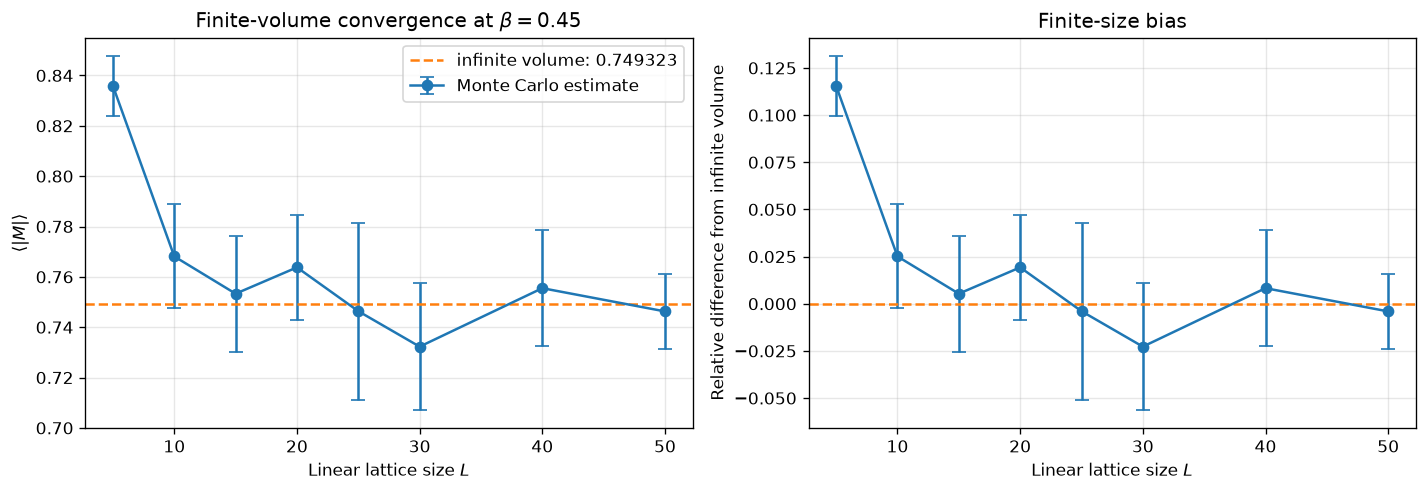

In [4]:
lattice_sizes_045 = [5, 10, 15, 20, 25, 30, 40, 50]
total_sweeps_045 = 3_000
equilibration_sweeps_045 = min(
    1_500,
    max(500, int(np.ceil(discard_sweeps_045))),
)
volume_seeds_045 = np.random.SeedSequence(452).spawn(len(lattice_sizes_045))
volume_results_045 = []

for L, seed_sequence in zip(lattice_sizes_045, volume_seeds_045):
    rng = np.random.default_rng(seed_sequence)
    lattice = initialize_lattice(L, startcold=True, rng=rng)
    spin_sum = int(np.sum(lattice))
    values = np.empty(total_sweeps_045 - equilibration_sweeps_045)

    for sweep in range(total_sweeps_045):
        for _ in range(lattice.size):
            _, delta_spin_sum = metropolis_update(lattice, beta_045, rng=rng)
            spin_sum += delta_spin_sum
        if sweep >= equilibration_sweeps_045:
            values[sweep - equilibration_sweeps_045] = abs(spin_sum / lattice.size)

    sweep_acf = normalized_acf_fft(values)
    tau_sweeps, _ = self_consistent_tau(sweep_acf)
    block_sweeps = max(5, int(np.ceil(10 * tau_sweeps)))
    block_sweeps = min(block_sweeps, len(values) // 10)
    n_blocks = len(values) // block_sweeps
    block_means = values[:n_blocks * block_sweeps].reshape(
        n_blocks, block_sweeps
    ).mean(axis=1)
    volume_results_045.append(
        (
            L,
            block_means.mean(),
            block_means.std(ddof=1) / np.sqrt(n_blocks),
            tau_sweeps,
            block_sweeps,
            n_blocks,
        )
    )

exact_magnetization_045 = (1 - np.sinh(2 * beta_045)**(-4))**(1 / 8)
sizes_045 = np.array([row[0] for row in volume_results_045])
means_045 = np.array([row[1] for row in volume_results_045])
errors_volume_045 = np.array([row[2] for row in volume_results_045])

print(f"Exact infinite-volume magnetization: {exact_magnetization_045:.8f}")
print(f"Equilibration discarded: {equilibration_sweeps_045} sweeps")
print(f"{'L':>4} {'mean |M|':>12} {'uncertainty':>14} {'tau [sweeps]':>14} "
      f"{'block [sweeps]':>16} {'blocks':>8}")
for L, mean_m, uncertainty, tau_sweeps, block_sweeps, n_blocks in volume_results_045:
    print(
        f"{L:4d} {mean_m:12.8f} {uncertainty:14.8f} "
        f"{tau_sweeps:14.2f} {block_sweeps:16d} {n_blocks:8d}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].errorbar(
    sizes_045,
    means_045,
    yerr=errors_volume_045,
    fmt="o-",
    capsize=4,
    label="Monte Carlo estimate",
)
axes[0].axhline(
    exact_magnetization_045,
    color="C1",
    ls="--",
    label=fr"infinite volume: {exact_magnetization_045:.6f}",
)
axes[0].set(
    xlabel="Linear lattice size $L$",
    ylabel=r"$\langle |M|\rangle$",
    title=fr"Finite-volume convergence at $\beta={beta_045}$",
)
axes[0].legend()

relative_difference_045 = (
    means_045 - exact_magnetization_045
) / exact_magnetization_045
axes[1].errorbar(
    sizes_045,
    relative_difference_045,
    yerr=errors_volume_045 / exact_magnetization_045,
    fmt="o-",
    capsize=4,
)
axes[1].axhline(0, color="C1", ls="--")
axes[1].set(
    xlabel="Linear lattice size $L$",
    ylabel="Relative difference from infinite volume",
    title="Finite-size bias",
)

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
